# 3 · A residual upscaler for the browser

`2_upscale_nn.ipynb` trained a plain CNN that makes the whole picture itself. This one is
**residual**: bicubic makes the picture, and the network only learns a correction that is
added to it. Its last layer starts at zero, so the untrained model *is* bicubic and
training can only improve on it. Steps:

1. **Data** - load the patch pairs.
2. **Model** - bicubic as a fixed convolution, plus a small learned correction.
3. **Speed** - is it fast enough for a live stream? Checked before training.
4. **Train** - and compare with bicubic after every epoch.
5. **Save** - write a checkpoint, check it loads back the same, run a whole frame.
6. **Export** - float32, float16, int8 and a bigger tile, each checked against torch.
7. **Skip unchanged tiles** - how many tiles of a desktop frame really need to run.

Needs: `0_data_preprocess.ipynb`. Results: `summary.md`, "The browser-shaped model".
Writes `checkpoints/upscale_web.pt`, which `5_upscale_geometry.ipynb` uses.

In [1]:
"""Settings."""

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image, ImageDraw

from helpers import metrics, models, patches, speed, tiles, training, webexport
from helpers.training import DATA_DIR, DEVICE

CHECKPOINT = training.CHECKPOINT_DIR / "upscale_web.pt"
FRAME_DIR = DATA_DIR / "synthetic"

# The network (see "2. Model")
WIDTHS = (32, 16)    # channels of the body's convolutions
STEM = 5             # kernel size of the first convolution; the ones after it are 3x3
SKIP = 5             # kernel size of the bicubic skip (bicubic x2 needs 4 taps; 5 is the smallest odd size)
MAX_EPOCHS = 500     # a safety limit; training stops once it has converged
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
SEED = 0

BENCH_RESOLUTIONS = [(480, 270), (640, 360), (960, 540), (1280, 720)]   # LR input sizes
BENCH_LR_SIZE = (320, 180)
BENCH_BATCHES = [1, 2, 4, 8, 16]
DEPLOY_STEP = 256    # a bigger tile, also published (fewer runs per frame)

training.seed_everything(SEED)

## 1. Data

`train` is what the model learns from, with random flips and rotations as free extra
examples. `val` is held out: every score below is measured on it.

The LR patches carry a halo of extra pixels, so the model's output is a bit too large;
`trim` cuts that border off before the loss and the scores.

device  cuda NVIDIA GeForce RTX 3090
scale   2
patch   72 px LR in (64 px + a halo of 4) -> 128 px HR out, 8 frames each
train  11117 patches from 697 sources
val     2369 patches from 149 sources
lr batch (32, 3, 72, 72)  hr batch (32, 3, 128, 128)


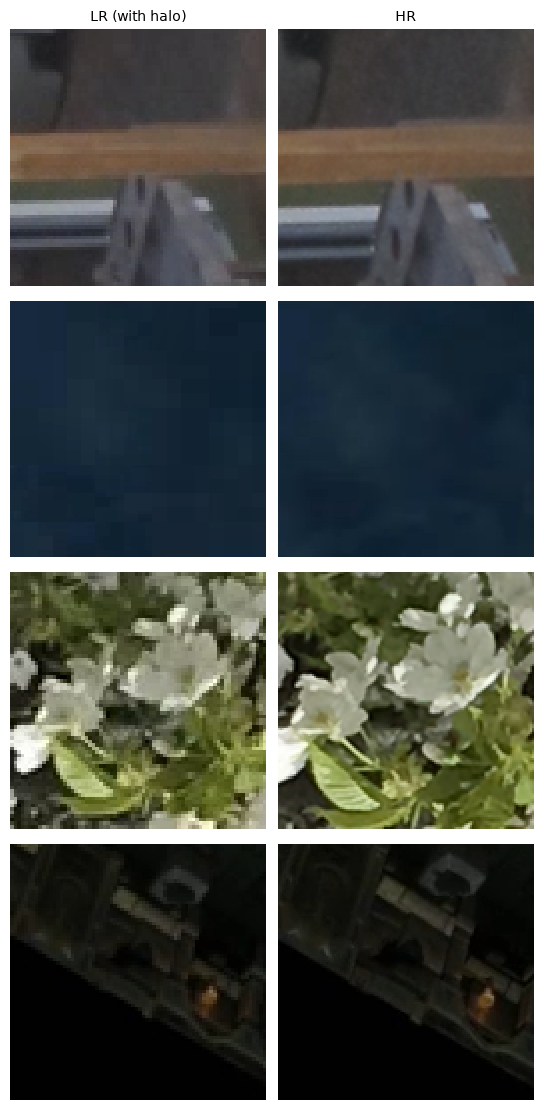

In [2]:
manifest = training.load_manifest()
training.describe(manifest)
SCALE = manifest["scale"]
train_loader, val_loader = training.loaders(DATA_DIR, manifest, BATCH_SIZE)
trim = training.trimmer(manifest)

lr_batch, hr_batch = next(iter(train_loader))
print("lr batch", tuple(lr_batch.shape), " hr batch", tuple(hr_batch.shape))
training.show_patches({"LR (with halo)": lr_batch[:4], "HR": hr_batch[:4]})

## 2. Model

    LR --> bicubic skip (fixed 5x5 conv) ---------------------------+
    LR --> conv 5x5 -> ReLU -> conv 3x3 -> ReLU -> output conv 3x3 --+--> add --> PixelShuffle --> HR

- **Bicubic as a convolution.** Bicubic x2 is linear and the same everywhere, which is
  what a convolution is: each of the 4 output sub-pixels is a fixed filter of the input
  (`models.BicubicSkip`, frozen). The browser runs `Conv` fast and `Resize` slowly.
- **Added at low resolution.** Both branches are added *before* the `PixelShuffle`: one
  shuffle, and a quarter of the pixels to add.
- **Starts as bicubic.** The output convolution starts at zero, so the untrained model is
  exactly bicubic, and the network only has to learn the correction.

**Halo.** The 5x5 reaches 2 pixels, each 3x3 after it 1: 4 in all, the halo of the
patches and of the client's tiles.

In [3]:
difference = models.check_skip_is_bicubic(SCALE, SKIP)
print(f"conv skip vs F.interpolate: {difference:.1e} apart (float32 rounding)")

model = models.PlainUpscaler(WIDTHS, STEM, SKIP, SCALE).to(DEVICE)
assert model.halo <= manifest["halo"], "the model reaches further than the patches' halo"
print(model)
print(f"{models.count_parameters(model):,} parameters ({models.count_parameters(model, learned_only=True):,} "
      f"learned), halo {model.halo}, {speed.macs_per_lr_pixel(model):,.0f} multiply-adds per LR pixel")

conv skip vs F.interpolate: 2.4e-07 apart (float32 rounding)


PlainUpscaler(
  (skip): BicubicSkip(
    (conv): Conv2d(3, 12, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
  )
  (shuffle): PixelShuffle(upscale_factor=2)
  (body): Sequential(
    (0): Conv2d(3, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (tail): Conv2d(16, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
)


9,696 parameters (8,796 learned), halo 4, 9,636 multiply-adds per LR pixel


In [4]:
"""Before training: the model must score exactly like bicubic."""

bicubic = models.Resize(SCALE).to(DEVICE)
baseline = training.evaluate(bicubic, val_loader, trim)
start = training.evaluate(model, val_loader, trim)
metrics.print_table({"bicubic": baseline, "untrained model": start})
assert abs(start["rgb"] - baseline["rgb"]) < 1e-3, "the model should start as bicubic"

                     wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic              37.30    36.38    47.06    47.27     35.00   0.9135
untrained model      37.30    36.38    47.06    47.27     35.00   0.9135


## 3. Speed - is it fast enough?

A model that misses the frame time is no use for a live stream, however good it looks.
Speed depends on the network's shape, not its weights, so it is checked before training:
if it is too slow, change `WIDTHS` and `STEM` now.

A batch of one is the honest number - frames arrive one at a time. A larger batch is
cheaper per frame, but each frame waits for the others.

In [5]:
"""One frame at a time, at the sizes a client asks for."""

model.eval()
print(f"{'output':>12}{'ms/frame':>10}   fits")
with torch.no_grad():
    for width, height in BENCH_RESOLUTIONS:
        x = torch.rand(1, 3, height, width, device=DEVICE)
        ms = speed.time_ms(lambda: model(x), seconds=1.0)
        print(f"{f'{width * SCALE}x{height * SCALE}':>12}{ms:10.1f}   {speed.frame_budget(ms)}")

      output  ms/frame   fits


     960x540       0.5   60 fps


    1280x720       0.8   60 fps


   1920x1080       1.7   60 fps


   2560x1440       3.0   60 fps


In [6]:
"""What a batch buys at 320x180 -> 640x360."""

per_frame = {}
with torch.no_grad():
    for batch in BENCH_BATCHES:
        x = torch.rand(batch, 3, BENCH_LR_SIZE[1], BENCH_LR_SIZE[0], device=DEVICE)
        per_frame[batch] = speed.time_ms(lambda: model(x), seconds=1.0) / batch

print(f"{'batch':>5}{'ms/frame':>10}{'vs batch 1':>12}")
for batch, ms in per_frame.items():
    print(f"{batch:5}{ms:10.2f}{per_frame[1] / ms:11.2f}x")

batch  ms/frame  vs batch 1
    1      0.26       1.00x
    2      0.21       1.25x
    4      0.20       1.33x
    8      0.19       1.38x
   16      0.19       1.41x


### What `Resize` costs

The same model exported twice - once with the skip as `F.interpolate` (a `Resize` node)
and once as the convolution - and timed on the desktop CPU. This is why the skip is a convolution.

In [7]:
class ResizeSkip(models.PlainUpscaler):
    """The same model with the skip as F.interpolate, which exports as a `Resize`."""

    def forward(self, x):
        return models.bicubic(x, self.scale) + self.shuffle(self.residual(x))


size = webexport.TILE_STEP + 2 * model.halo
comparison_dir = training.CHECKPOINT_DIR / "comparison"
for name, variant in {"conv skip": model, "Resize skip": ResizeSkip(WIDTHS, STEM, SKIP, SCALE)}.items():
    info = webexport.export(variant, f"skip_{name.split()[0].lower()}.onnx", size, models_dir=comparison_dir)
    print(f"{name:<12}", webexport.summary_line(info, webexport.time_graph(info["path"], size)))

conv skip    skip_conv.onnx                                         39.3 KB    0.94 ms   Addx1, Convx4, DepthToSpacex1, Relux2


Resize skip  skip_resize.onnx                                       35.8 KB   13.85 ms   Addx1, Constantx1, Convx3, DepthToSpacex1, Relux2, Resizex1   OUTSIDE BUDGET: Resize


### On the target hardware

Spec sheets state compute in **TOPS** (10¹² operations per second; a multiply-add is 2).
`webexport.count_work` counts the operations and the memory traffic in the ONNX graph of
one client tile (640x360 out, plus the halo); a frame costs that times its tiles.

The runtime is a **roofline** estimate: a device needs at least *operations / peak
compute* and at least *bytes / bandwidth*, whichever is slower. This computer's GPU is
timed to see what share of its peak it reaches, and every device in `speed.HARDWARE` is
assumed to reach the same share. A browser usually reaches less, so read it as a best
case; the benchmark page, opened on the device, gives the real number.

In [8]:
"""The work in one client tile, counted in its ONNX graph, and the TOPS a stream needs."""

plan = tiles.plan_tiling((1920, 1080), scale=SCALE, halo=model.halo)
tile_shape = plan["input"][2:]   # (height, width) of one tile, halo included
# into checkpoints/, not dist/, so the benchmark page does not list it
tile_graph = webexport.export(model, "speed_check_web.onnx", tile_shape, halo=model.halo,
                              models_dir=training.CHECKPOINT_DIR / "speed")
work = webexport.count_work(tile_graph["path"])
ops_per_pixel = work["operations"] / work["input_pixels"]   # every convolution keeps the size
bytes_per_pixel = work["activation_bytes"] / work["input_pixels"]
print(f"one {tile_shape[1]}x{tile_shape[0]} tile: {work['operations'] / 1e9:.2f} G operations, "
      f"{work['activation_bytes'] / 1e6:.0f} MB of activations moved, {work['weight_bytes'] / 1e3:.0f} KB of weights")
for op, operations in work["by_op"].items():
    print(f"  {op:<13}{operations / 1e9:8.3f} G  ({operations / work['operations']:.1%})")
print(f"per LR pixel: {ops_per_pixel:,.0f} operations, {bytes_per_pixel:,.0f} bytes moved")


def frame_work(width, height):
    """Operations and bytes for one width x height output frame, cut into the client's tiles."""
    plan = tiles.plan_tiling((width, height), scale=SCALE, halo=model.halo)
    pixels = plan["runs"] * plan["input"][2] * plan["input"][3]   # LR pixels computed, halos included
    return {"runs": plan["runs"], "operations": pixels * ops_per_pixel,
            "bytes": pixels * bytes_per_pixel + plan["runs"] * work["weight_bytes"]}


print(f"\n{'output':>11}{'tiles':>7}{'G ops/frame':>13}{'TOPS at 30 fps':>16}{'TOPS at 60 fps':>16}")
for width, height in BENCH_RESOLUTIONS:
    frame = frame_work(width * SCALE, height * SCALE)
    print(f"{f'{width * SCALE}x{height * SCALE}':>11}{frame['runs']:>7}{frame['operations'] / 1e9:>13.1f}"
          f"{frame['operations'] * 30 / 1e12:>16.3f}{frame['operations'] * 60 / 1e12:>16.3f}")

one 328x188 tile: 1.20 G operations, 70 MB of activations moved, 39 KB of weights
  Conv            1.192 G  (99.7%)
  Relu            0.003 G  (0.2%)
  Add             0.001 G  (0.1%)
  DepthToSpace    0.000 G  (0.0%)
per LR pixel: 19,392 operations, 1,128 bytes moved

     output  tiles  G ops/frame  TOPS at 30 fps  TOPS at 60 fps
    960x540      2          2.7           0.080           0.160
   1280x720      4          4.8           0.143           0.287
  1920x1080      9         10.8           0.323           0.646
  2560x1440     16         19.1           0.574           1.148


In [9]:
"""Simulated runtime per frame on the target hardware (float32)."""

# Calibrate: the share of its peak this GPU reaches, on one whole 1080p frame (no tiles)
if DEVICE.type == "cuda":
    x = torch.rand(1, 3, 540, 960, device=DEVICE)
    with torch.no_grad():
        measured_ms = speed.time_ms(lambda: model.eval()(x), seconds=1.0)
    whole_frame = {"operations": 960 * 540 * ops_per_pixel,
                   "bytes": 960 * 540 * bytes_per_pixel + work["weight_bytes"]}
    best_ms, _ = speed.roofline_ms(whole_frame, *speed.HARDWARE[speed.THIS_GPU])
    efficiency = best_ms / measured_ms
    print(f"{speed.THIS_GPU}: measured {measured_ms:.2f} ms per 1080p frame, the roofline says at least "
          f"{best_ms:.2f} ms, so it reaches {efficiency:.0%} of its peak "
          f"({whole_frame['operations'] / (measured_ms / 1000) / 1e12:.1f} TOPS)")
else:
    efficiency = 1.0
    print("no GPU here to calibrate on: the estimates below are the roofline itself, a best case")
cpu_ms = webexport.time_graph(tile_graph["path"], tile_shape)
print(f"this CPU (onnxruntime): {cpu_ms:.1f} ms per tile, {work['operations'] / (cpu_ms / 1000) / 1e12:.3f} TOPS")

resolutions = [(width * SCALE, height * SCALE) for width, height in BENCH_RESOLUTIONS]
print(f"\nestimated ms per frame at {efficiency:.0%} of the peak (c = compute-bound, m = memory-bound)")
print(f"{'':<36}" + "".join(f"{f'{width}x{height}':>14}" for width, height in resolutions) + "   1080p")
for name, (tflops, gbps) in speed.HARDWARE.items():
    row = f"{name:<36}"
    for width, height in resolutions:
        best_ms, limit = speed.roofline_ms(frame_work(width, height), tflops, gbps)
        row += f"{best_ms / efficiency:>10.1f} ({limit[0]})"
    full_hd_ms = speed.roofline_ms(frame_work(1920, 1080), tflops, gbps)[0] / efficiency
    print(f"{row}   {speed.frame_budget(full_hd_ms)}")

NVIDIA RTX 3090: measured 1.69 ms per 1080p frame, the roofline says at least 0.62 ms, so it reaches 37% of its peak (6.0 TOPS)


this CPU (onnxruntime): 3.1 ms per tile, 0.390 TOPS

estimated ms per frame at 37% of the peak (c = compute-bound, m = memory-bound)
                                           960x540      1280x720     1920x1080     2560x1440   1080p
Intel UHD 620 (laptop iGPU)               17.2 (c)      30.7 (c)      69.1 (c)     122.9 (c)   under 30 fps
Intel Iris Xe, 96 EU (laptop iGPU)         6.2 (m)      11.0 (m)      24.8 (m)      44.2 (m)   30 fps
Apple M1, 8-core GPU                       6.2 (m)      11.0 (m)      24.8 (m)      44.2 (m)   30 fps
NVIDIA GTX 1650                            3.3 (m)       5.9 (m)      13.2 (m)      23.5 (m)   60 fps
NVIDIA RTX 3060                            1.2 (m)       2.1 (m)       4.7 (m)       8.3 (m)   60 fps
NVIDIA RTX 3090                            0.4 (m)       0.8 (m)       1.8 (m)       3.2 (m)   60 fps


## 4. Train

Same recipe as `2_upscale_nn.ipynb`: the loss is `metrics.ssim_l1_loss` (0.84 x (1 - SSIM
on luma) + 0.16 x L1 on RGB), and after every epoch the epoch with the best luma SSIM
(`ssim-y`) is kept. Training runs until the score stops improving, halving the learning
rate at every plateau; `MAX_EPOCHS` is only a safety limit.

The model starts at bicubic, so its curve starts on the bicubic line, not far below it.

Training until the model stops improving, at most 500 epochs. Untrained model: val_ssim_y: 0.9135.
Learning rate 1.0e-03, halved after 6 epochs without improvement; training stops when 1.0e-05 does not help either.
Epoch 1/500


32/347 [==>...........................] - 1s 16ms/step - loss: 0.0996

75/347 [======>.......................] - 1s 14ms/step - loss: 0.1018

118/347 [==========>...................] - 2s 13ms/step - loss: 0.1011

162/347 [==============>...............] - 2s 13ms/step - loss: 0.1017

...

185/347 [===============>..............] - 2s 11ms/step - loss: 0.0878

231/347 [===================>..........] - 3s 11ms/step - loss: 0.0873

276/347 [=======================>......] - 3s 11ms/step - loss: 0.0883

321/347 [===========================>..] - 4s 11ms/step - loss: 0.0882

347/347 [==============================] - 4s 12ms/step - loss: 0.0883 - val_wpsnr: 37.9254 - val_psnr_y: 37.0917 - val_psnr_u: 44.5404 - val_psnr_v: 45.3521 - val_psnr_rgb: 35.5762 - val_ssim_y: 0.9265 - learning_rate: 1.0e-05
Epoch 150: val_ssim_y did not improve from 0.9265 (6 of 6 epochs without improvement)
Epoch 150: stopping (converged - no improvement in 6 epochs, even at the smallest learning rate)
Restoring model weights from the end of the best epoch: 144 (val_ssim_y: 0.9265, +0.0130 over the untrained model). Training took 150 epochs, 10.9 min.


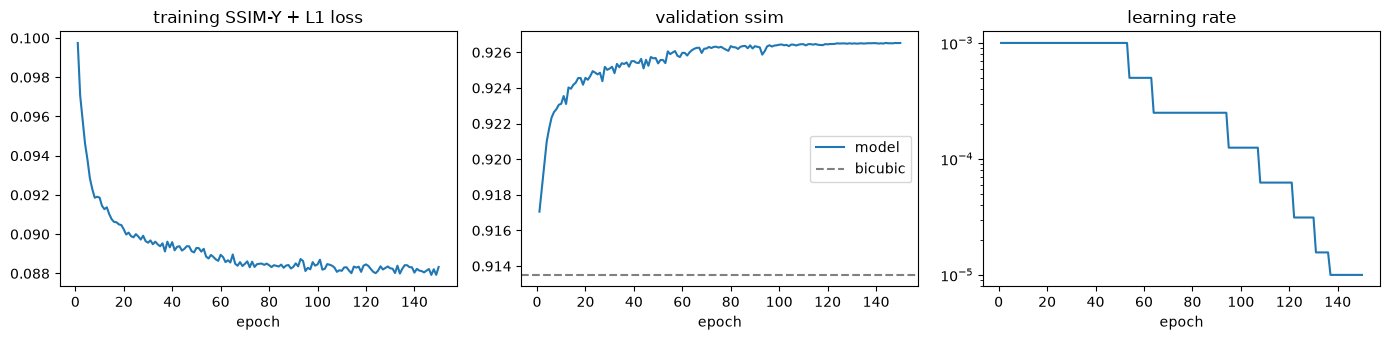

                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic             37.30    36.38    47.06    47.27     35.00   0.9135   +0.0000 ssim-y vs bicubic
model               37.96    37.13    44.59    45.38     35.61   0.9265   +0.0130 ssim-y vs bicubic


In [10]:
history, best = training.train(model, train_loader, val_loader, trim, MAX_EPOCHS,
                               learning_rate=LEARNING_RATE, loss_fn=metrics.ssim_l1_loss, select="ssim")
training.plot_history(history, baseline, key="ssim", loss_name="SSIM-Y + L1 loss")

final = training.evaluate(model, val_loader, trim)
metrics.print_table({"bicubic": baseline, "model": final},
                    extra=lambda name, s: f"   {s['ssim'] - baseline['ssim']:+.4f} ssim-y vs bicubic")

### What it looks like

Check text lines and window edges - that is what a desktop stream is made of.

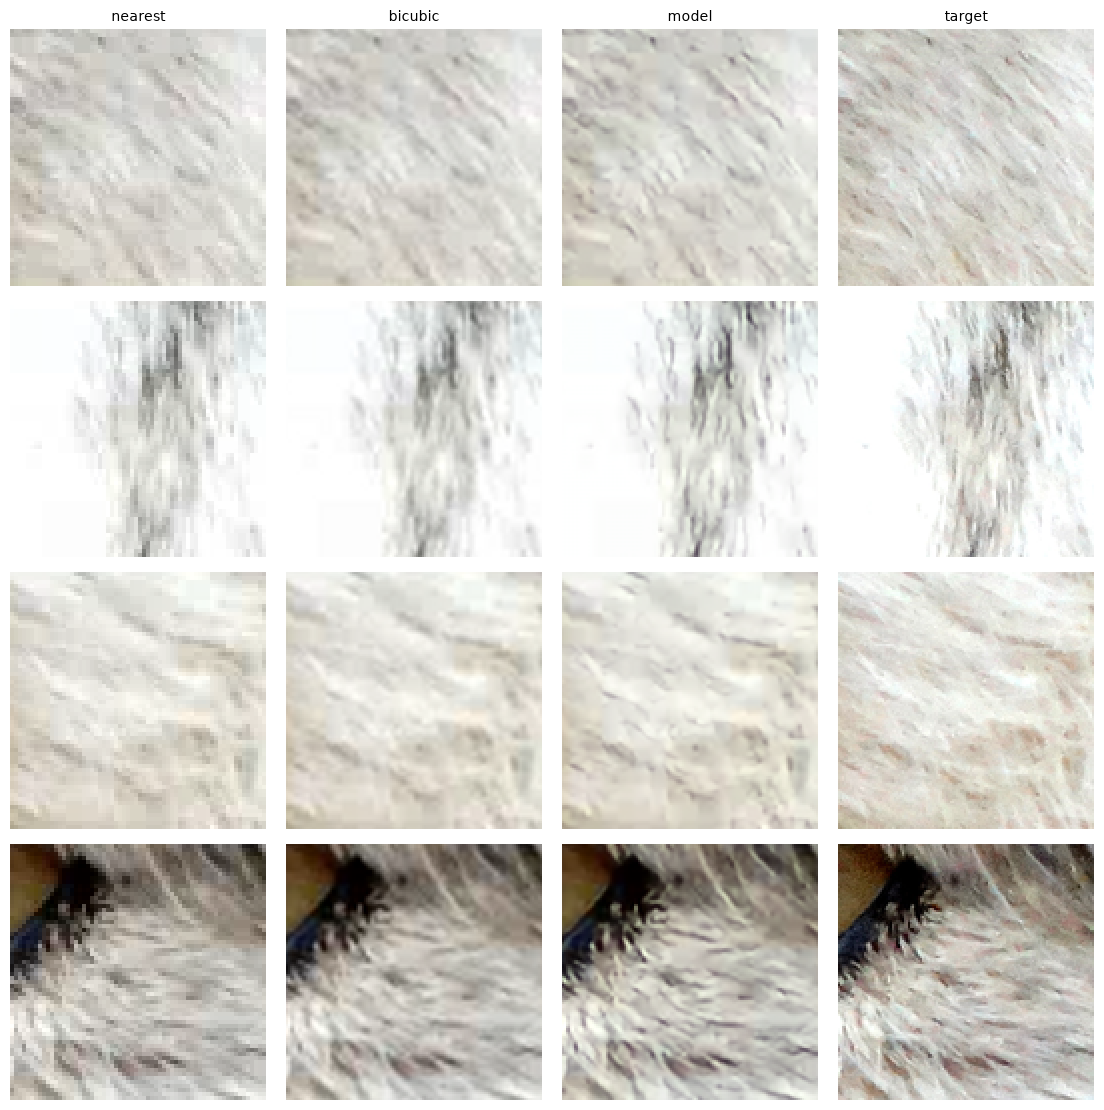

In [11]:
lr, hr = next(iter(val_loader))
lr, hr = lr[:4].to(DEVICE), hr[:4].to(DEVICE)
with torch.no_grad():
    training.show_patches({
        "nearest": trim(F.interpolate(lr, scale_factor=SCALE, mode="nearest")),
        "bicubic": trim(models.bicubic(lr, SCALE)),
        "model": trim(model.eval()(lr)),
        "target": hr,
    })

## 5. Save and reload

The checkpoint holds the weights *and* everything needed to rebuild the model. We load
it into a fresh model and check it computes the same thing.

In [12]:
training.save_checkpoint(CHECKPOINT, model, architecture="PlainUpscaler", widths=list(WIDTHS),
                         stem=STEM, skip=SKIP, scale=SCALE, halo=model.halo, loss="ssim_l1_loss",
                         select="ssim", epochs=len(history), best_epoch=best["epoch"], val=final,
                         val_bicubic=baseline, degradation=manifest["degradation"])

checkpoint = training.load_checkpoint(CHECKPOINT)
loaded = models.PlainUpscaler(tuple(checkpoint["widths"]), checkpoint["stem"],
                              checkpoint["skip"], checkpoint["scale"]).to(DEVICE)
loaded.load_state_dict(checkpoint["state_dict"])
training.assert_same_model(model, loaded)
print("reloaded model is identical")

saved /home/henrik/desktop-streamer-ai/src/upscale/checkpoints/upscale_web.pt (43 KB)
reloaded model is identical


### A whole frame

The model is fully convolutional, so it runs on a picture of any size, not only patches.

                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic             25.82    25.09    29.55    29.01     23.92   0.9437
model               27.29    26.79    29.57    29.02     24.97   0.9628


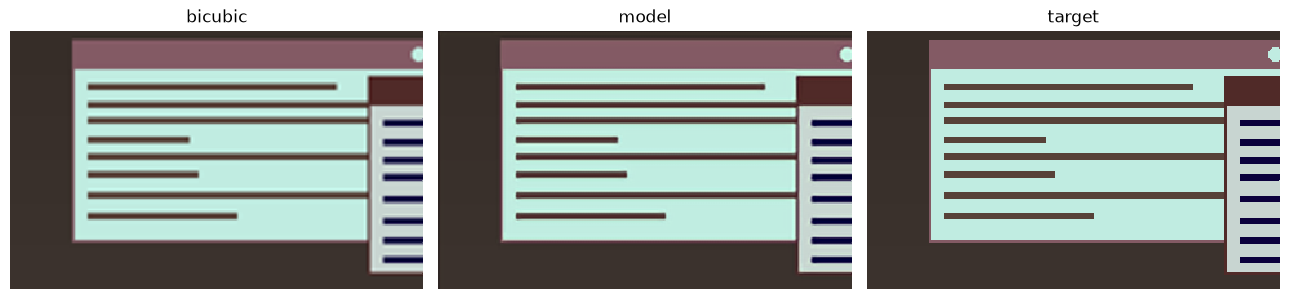

In [13]:
truth = Image.open(sorted(FRAME_DIR.glob("*.png"))[0]).convert("RGB")
truth = truth.crop((0, 0, truth.width - truth.width % SCALE, truth.height - truth.height % SCALE))
small = truth.resize((truth.width // SCALE, truth.height // SCALE), Image.BICUBIC)

with torch.no_grad():
    upscaled = loaded.eval()(training.to_tensor(small))
target = training.to_tensor(truth)
metrics.print_table({"bicubic": metrics.report(models.bicubic(training.to_tensor(small), SCALE), target),
                     "model": metrics.report(upscaled, target)})
Image.fromarray(training.to_image(upscaled)).save(training.SAMPLE_DIR / "upscaled_web.png")

box = (slice(0, 200), slice(0, 320))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
panels = {"bicubic": np.asarray(small.resize(truth.size, Image.BICUBIC)),
          "model": training.to_image(upscaled), "target": np.asarray(truth)}
for ax, (name, image) in zip(axes, panels.items()):
    ax.imshow(image[box], interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 6. Export for the browser

Four graphs are published, each checked against the torch model first:

- **float32** at the page's 128 step - comparable with every other model on the page;
- **float16** - half the size; the desktop CPU has no float16 kernels, so it is only
  faster on a GPU;
- **int8** - smaller again, but its extra nodes are outside the browser's fast operator
  set, so it is much *slower* in the browser. Published to show that;
- **float16 at step 256** - a bigger tile means fewer runs per frame.

In [14]:
halo = checkpoint["halo"]
size = webexport.TILE_STEP + 2 * halo
label = f"web {'-'.join(str(w) for w in WIDTHS)}"
val_lr, _ = patches.load(DATA_DIR, "val", manifest)
train_lr, _ = patches.load(DATA_DIR, "train", manifest, count=48)


def tile_from(patch, edge):
    """A real uint8 patch as a float (1, 3, edge, edge) array, its border repeated to fill."""
    x = patch.transpose(2, 0, 1)[None].astype(np.float32) / 255.0
    return np.pad(x, ((0, 0), (0, 0), (0, edge - patch.shape[0]), (0, edge - patch.shape[1])), mode="edge")


noise = np.random.rand(1, 3, size, size).astype(np.float32)

fp32 = webexport.export(loaded, f"upscale_web_tile{webexport.TILE_STEP}.onnx", size,
                        label=f"{label} fp32", halo=halo)
webexport.check_graph(fp32["path"], loaded, noise)

fp16 = webexport.to_float16(fp32, f"upscale_web_fp16_tile{webexport.TILE_STEP}.onnx")
webexport.write_metadata(fp16["path"], {"label": f"{label} fp16"})
webexport.check_graph(fp16["path"], loaded, noise, np.float16, tolerance=4e-3)

# int8 learns its value ranges from real patches, so it is also checked on a real patch
int8 = webexport.to_int8(fp32, f"upscale_web_int8_tile{webexport.TILE_STEP}.onnx",
                         [tile_from(p, size) for p in train_lr])
webexport.write_metadata(int8["path"], {"label": f"{label} int8 (Q/DQ, outside the budget)"})
webexport.check_graph(int8["path"], loaded, tile_from(val_lr[0], size), tolerance=2e-2)

deploy_size = DEPLOY_STEP + 2 * halo
deploy = webexport.export(loaded, f"upscale_webbig_tile{DEPLOY_STEP}.onnx", deploy_size, halo=halo)
deploy = webexport.to_float16(deploy, f"upscale_webbig_tile{DEPLOY_STEP}.onnx")
webexport.write_metadata(deploy["path"], {"label": f"{label} fp16, step {DEPLOY_STEP}"})
webexport.check_graph(deploy["path"], loaded, np.random.rand(1, 3, deploy_size, deploy_size).astype(np.float32),
                      np.float16, tolerance=4e-3)

for info, shape, dtype in [(fp32, size, np.float32), (fp16, size, np.float16),
                           (int8, size, np.float32), (deploy, deploy_size, np.float16)]:
    ms = webexport.time_graph(info["path"], shape, dtype)
    webexport.annotate(info, cpu_ms=round(ms, 2))
    print(webexport.summary_line(info, ms))

upscale_web_tile128.onnx                               39.3 KB    0.92 ms   Addx1, Convx4, DepthToSpacex1, Relux2


upscale_web_fp16_tile128.onnx                          20.7 KB    0.92 ms   Addx1, Convx4, DepthToSpacex1, Relux2


upscale_web_int8_tile128.onnx                          16.8 KB    0.74 ms   Addx1, Convx4, DepthToSpacex1, DequantizeLinearx13, QuantizeLinearx6   OUTSIDE BUDGET: DequantizeLinear, QuantizeLinear


upscale_webbig_tile256.onnx                            20.7 KB    3.60 ms   Addx1, Convx4, DepthToSpacex1, Relux2


In [15]:
"""Quality of each precision, measured by running the ONNX graph itself."""

eval_dir = training.CHECKPOINT_DIR / "evaluation"
any_size = webexport.export(loaded, "web_dynamic.onnx", manifest["input_lr"], halo=halo,
                            dynamic=True, models_dir=eval_dir)
versions = {
    "float32": (any_size, np.float32),
    "float16": (webexport.to_float16(any_size, "web_dynamic_fp16.onnx", models_dir=eval_dir), np.float16),
    "int8": (webexport.to_int8(any_size, "web_dynamic_int8.onnx",
                               [tile_from(p, p.shape[0]) for p in train_lr], models_dir=eval_dir), np.float32),
}
results = {name: training.evaluate(webexport.OnnxModel(info["path"], dtype), val_loader, trim)
           for name, (info, dtype) in versions.items()}
metrics.print_table(results)

                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
float32             37.96    37.13    44.59    45.38     35.61   0.9265
float16             37.96    37.13    44.57    45.37     35.60   0.9265
int8                37.67    36.84    44.13    44.77     35.31   0.9250


## 7. Skip the tiles that did not change

The biggest saving is not in the model at all: on a desktop, most of the screen is the
same as in the previous frame. A tile whose input did not change has the same output,
so it does not need to run. Below, on a drawn desktop with a dragged window, a moving
cursor and a playing video: how many tiles change per frame.

In [16]:
def desktop_sequence(count, size=(1920, 1080), seed=SEED):
    """Frames of a drawn desktop: still windows, one dragged window, a cursor, a video."""
    rng = np.random.default_rng(seed)
    width, height = size
    background = Image.new("RGB", size, (32, 36, 44))
    draw = ImageDraw.Draw(background)
    for y in range(height):
        draw.line([(0, y), (width, y)], fill=(32 + y // 40, 36 + y // 40, 44 + y // 40))
    for index in range(3):
        x, y = 60 + index * 520, 80 + index * 90
        draw.rectangle([x, y, x + 460, y + 620], fill=(238, 238, 240), outline=(90, 110, 160), width=2)
        draw.rectangle([x, y, x + 460, y + 30], fill=(90, 110, 160))
        for row in range(y + 50, y + 600, 16):
            draw.rectangle([x + 16, row, x + 16 + int(rng.integers(120, 420)), row + 5], fill=(40, 40, 48))

    frames = []
    for index in range(count):
        frame = background.copy()
        drawing = ImageDraw.Draw(frame)
        x, y = 1180 + 6 * index, 420 + 3 * index                     # dragged window
        drawing.rectangle([x, y, x + 520, y + 380], fill=(250, 250, 252), outline=(160, 90, 90), width=2)
        drawing.rectangle([x, y, x + 520, y + 28], fill=(160, 90, 90))
        video = rng.integers(0, 255, (180, 320, 3), dtype=np.uint8)  # video playing
        frame.paste(Image.fromarray(video).resize((640, 360), Image.NEAREST), (200, 620))
        cx, cy = 900 + 11 * index, 300 + 7 * index                   # cursor
        drawing.polygon([(cx, cy), (cx + 14, cy + 40), (cx + 22, cy + 22)], fill=(255, 255, 255))
        frames.append(frame)
    return frames


def changed_tiles(frames, step):
    """Average share of LR tiles that differ from the previous frame."""
    low = [np.asarray(f.resize((f.width // SCALE, f.height // SCALE), Image.BICUBIC)) for f in frames]
    rows, cols = -(-low[0].shape[0] // step), -(-low[0].shape[1] // step)
    shares = []
    for before, now in zip(low, low[1:]):
        changed = sum(not np.array_equal(now[r * step:(r + 1) * step, c * step:(c + 1) * step],
                                         before[r * step:(r + 1) * step, c * step:(c + 1) * step])
                      for r in range(rows) for c in range(cols))
        shares.append(changed / (rows * cols))
    return float(np.mean(shares)), rows * cols


frames = desktop_sequence(24)
BROWSER_MS = {128: 0.190, 256: 0.424}   # ms per tile, measured in the browser (summary.md)
print(f"{'step':>5}{'tiles':>7}{'changed':>9}{'all tiles':>11}{'changed only':>14}")
for step, ms in BROWSER_MS.items():
    share, tiles = changed_tiles(frames, step)
    print(f"{step:5}{tiles:7}{share:9.0%}{tiles * ms:8.1f} ms{tiles * share * ms:11.1f} ms")

 step  tiles  changed  all tiles  changed only


  128     40      44%     7.6 ms        3.3 ms


  256     12      54%     5.1 ms        2.8 ms
